In [ ]:
# CELDA 1: Importaciones y configuración inicial
# Cálculos
import numpy as np
from scipy.special import zeta
from scipy.optimize import minimize_scalar
from scipy.stats import ks_2samp

# Graficación
from matplotlib.ticker import AutoMinorLocator
from matplotlib import pyplot as plt
matplotlib.use('QtAgg')                         # Uses the Qt6 graphic motor

# Configuración de estilo para las gráficas
# --- Grafica --- (sacado y modificado de un proyecto propio anterior)
plt.rcdefaults()                                # Restarts the configuration (so new changes may appear)
plt.close('all')                                # Closes previously opened graphs (so new changes may appear)

# Grid and axes structure

plt.rcParams['font.family'] = 'sans-serif'      # Font
plt.rcParams['font.size'] = 12                  # Font Size
plt.rcParams['figure.facecolor'] = 'white'      # Background behind graphs
plt.rcParams['axes.facecolor'] = 'white'        # Background on graphs
plt.rcParams['text.color'] = 'black'            # Text color black
plt.rcParams['axes.labelcolor'] = 'black'       # Label color black
plt.rcParams['xtick.color'] = 'black'           # X ticks/values color black
plt.rcParams['ytick.color'] = 'black'           # Y ticks/values color black
plt.rcParams['axes.edgecolor'] = 'black'        # Edge color black
plt.rcParams['axes.linewidth'] = 1.5            # Edge linewidth
plt.rcParams['axes.spines.top'] = True          # Show top spine (axe)
plt.rcParams['axes.spines.right'] = True        # Show right spine (axe)
plt.rcParams['lines.linewidth'] = 2             # Default function's graph linewidth
plt.rcParams['axes.grid'] = True                # Enables the grid
plt.rcParams['grid.color'] = 'gray'             # Grid color gray
plt.rcParams['grid.linestyle'] = '-'            # Grid linestyle
plt.rcParams['grid.alpha'] = 0.25               # Grid alpha
plt.rcParams['axes.axisbelow'] = True           # Send the grid below the graph
ax=plt.gca()                                    # Returns the Axes length
ax.xaxis.set_minor_locator(AutoMinorLocator())  # Intermedian values on X Axis
ax.yaxis.set_minor_locator(AutoMinorLocator())  # Intermedian values on Y Axis
ax.tick_params(which='both', direction='in', top=True, right=True)  # Intermedian values inside the graph

In [ ]:
# CELDA 2: Simulación del proceso (Secuencia estricta del algoritmo)
def simular_guerrilla_estricto(N=10000, nu=0.01, pasos=2000000):
    """
    Simula el proceso estocástico siguiendo exactamente los 3 pasos
    de la página 17-18 del artículo.
    """
    counts = {1: N} 
    
    for _ in range(pasos):
        # PASO (1): Selección inicial de la unidad 'i' candidata
        r1 = np.random.randint(1, N + 1)
        acc = 0
        for s, c in counts.items():
            acc += s * c
            if acc >= r1:
                s1 = s
                break
                
        # PASO (2): Lanzamiento de moneda (v) para decidir el destino de 'i'
        if np.random.rand() < nu:
            # --- FRAGMENTACIÓN ---
            # PASO (3): Lanzamiento de moneda f[s_i] (que es 1 en el modelo básico)
            # f_s1 = 1.0 
            # if np.random.rand() < f_s1:
            if s1 > 1:
                counts[s1] -= 1
                if counts[s1] == 0:
                    del counts[s1]
                counts[1] = counts.get(1, 0) + s1
                
        else:
            # --- COALESCENCIA ---
            # Para la coalescencia, necesitamos una segunda unidad 'j' con la cual interactuar
            r2 = np.random.randint(1, N + 1)
            acc = 0
            for s, c in counts.items():
                acc += s * c
                if acc >= r2:
                    s2 = s
                    break
                    
            # PASO (3): Lanzamiento de moneda f[s_i] * f[s_j] (que es 1*1 = 1 en el modelo básico)
            # f_s1_s2 = 1.0 * 1.0
            # if np.random.rand() < f_s1_s2:
            
            # Fusión de unidades (asegurando que no se fusione consigo misma)
            if s1 == s2:
                if np.random.rand() < (1.0 / counts[s1]):
                    continue # Era la misma unidad física, se aborta
                else:
                    counts[s1] -= 2
                    if counts[s1] == 0:
                        del counts[s1]
                    counts[s1 + s2] = counts.get(s1 + s2, 0) + 1
            else:
                counts[s1] -= 1
                if counts[s1] == 0:
                    del counts[s1]
                counts[s2] -= 1
                if counts[s2] == 0:
                    del counts[s2]
                counts[s1 + s2] = counts.get(s1 + s2, 0) + 1
                
    # Reconstruir la muestra observada al final del tiempo (estado estacionario)
    muestra = []
    for s, c in counts.items():
        muestra.extend([s] * c)
    return np.array(muestra)

In [8]:
# CELDA 3: Herramientas de estimación estadística robusta

def log_likelihood_discreto(alpha, datos, x_min):
    """
    Calcula la log-verosimilitud negativa para la ley de potencias discreta.
    """
    if alpha <= 1.0:
        return np.inf
    n = len(datos)
    zeta_val = zeta(alpha, x_min)
    log_l = -n * np.log(zeta_val) - alpha * np.sum(np.log(datos))
    return -log_l 

def estimar_dml(datos, x_min):
    """
    Encuentra el exponente alfa que maximiza la verosimilitud (DML).
    """
    datos_filtrados = datos[datos >= x_min]
    if len(datos_filtrados) < 10:
        return None, np.inf
    
    res = minimize_scalar(log_likelihood_discreto, bounds=(1.1, 5.0), 
                          args=(datos_filtrados, x_min), method='bounded')
    return res.x, res.fun

def encontrar_mejor_xmin_y_alfa(datos, x_min_max=20):
    """
    Aplica el test de Kolmogorov-Smirnov para encontrar el mejor x_min.
    """
    mejor_ks = np.inf
    mejor_alpha = None
    mejor_xmin = None
    
    for x_min in range(1, x_min_max + 1):
        datos_sub = datos[datos >= x_min]
        if len(datos_sub) < 20:
            break
            
        alpha_est, _ = estimar_dml(datos_sub, x_min)
        if alpha_est is None:
            continue
            
        # Generar distribución teórica para comparar
        k_vals = np.arange(x_min, np.max(datos) + 1)
        probs = (k_vals ** (-alpha_est)) / zeta(alpha_est, x_min)
        probs = probs / np.sum(probs) # Normalizar
        
        muestra_teorica = np.random.choice(k_vals, size=len(datos_sub), p=probs)
        ks_stat, _ = ks_2samp(datos_sub, muestra_teorica)
        
        if ks_stat < mejor_ks:
            mejor_ks = ks_stat
            mejor_alpha = alpha_est
            mejor_xmin = x_min
            
    return mejor_alpha, mejor_xmin

--- Ejecutando simulación para ν = 0.005 ---
Resultado: α óptimo = 2.649 | x_min = 1

--- Ejecutando simulación para ν = 0.01 ---
Resultado: α óptimo = 2.785 | x_min = 1

--- Ejecutando simulación para ν = 0.05 ---
Resultado: α óptimo = 2.885 | x_min = 1

--- Ejecutando simulación para ν = 0.1 ---
Resultado: α óptimo = 2.842 | x_min = 1



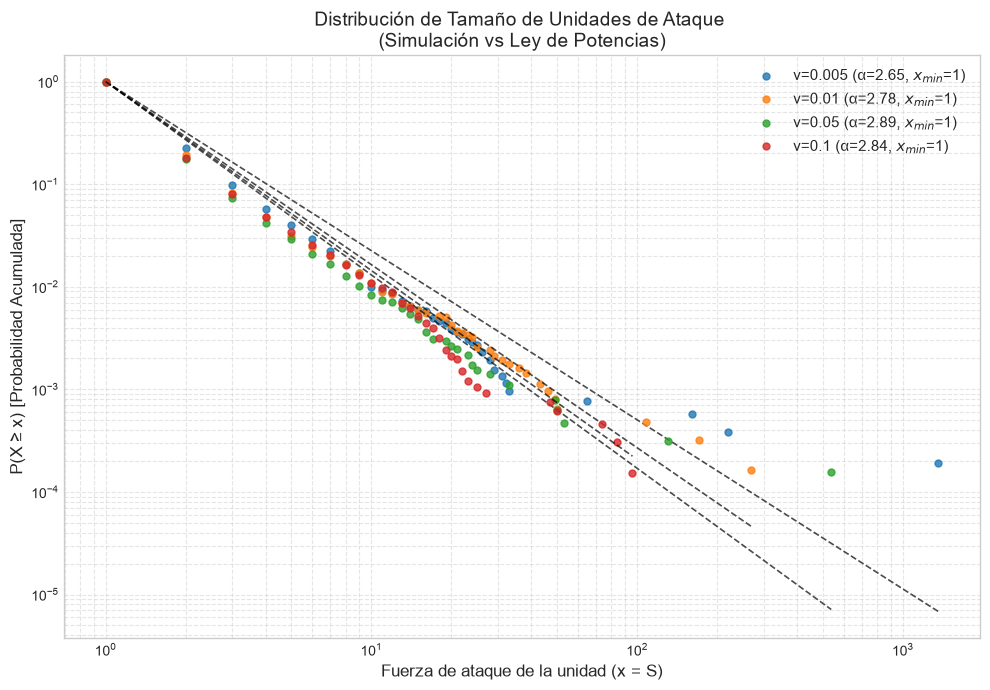

In [14]:
# CELDA 4: Ejecución de experimentos y visualización

# Parámetros del experimento
N_total = 10000      # Cumple con la recomendación de "más de 10000 unidades"
pasos_sim = 2000000  # Tiempo suficiente para estado estacionario
valores_nu = [0.005,0.01, 0.05, 0.1] # Variación del parámetro ν para el análisis

plt.figure(figsize=(10, 7))

for nu in valores_nu:
    print(f"--- Ejecutando simulación para ν = {nu} ---")
    
    # 1. Ejecutar simulación
    datos_muestra = simular_guerrilla(N=N_total, nu=nu, pasos=pasos_sim)
    
    # 2. Análisis estadístico
    alfa_dml, xmin_opt = encontrar_mejor_xmin_y_alfa(datos_muestra)
    print(f"Resultado: α óptimo = {alfa_dml:.3f} | x_min = {xmin_opt}\n")
    
    # 3. Preparar datos para gráfica P(X >= x)
    valores_unicos, conteos = np.unique(datos_muestra, return_counts=True)
    cdf_acumulada = np.cumsum(conteos[::-1])[::-1] / len(datos_muestra)
    
    # Graficar puntos empíricos
    plt.loglog(valores_unicos, cdf_acumulada, 'o', 
               label=f'ν={nu} (α={alfa_dml:.2f}, $x_{{min}}$={xmin_opt})', 
               markersize=5, alpha=0.8)
    
    # Graficar línea de tendencia teórica a partir de x_min
    if alfa_dml is not None and xmin_opt is not None:
        x_linea = np.linspace(xmin_opt, np.max(valores_unicos), 100)
        idx_xmin = np.where(valores_unicos == xmin_opt)[0][0]
        y_linea = (x_linea / xmin_opt) ** (-(alfa_dml - 1)) * cdf_acumulada[idx_xmin]
        plt.loglog(x_linea, y_linea, '--', color='black', linewidth=1.2, alpha=0.7)

# Configuración final de la gráfica
plt.xlabel('Fuerza de ataque de la unidad (x = S)', fontsize=12)
plt.ylabel('P(X ≥ x) [Probabilidad Acumulada]', fontsize=12)
plt.title('Distribución de Tamaño de Unidades de Ataque \n(Simulación vs Ley de Potencias)', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()